# ADS1299 八通道 EEG 数据处理（MNE）

电极顺序 **CH1–CH8** 对应：**PO7, PO3, POz, PO4, PO8, O1, Oz, O2**（枕顶区）。  
默认采样率 **500 Hz**（与固件一致）；若文件头中不同，以 `raw.info['sfreq']` 为准。

**数据格式**：`FIFO_plot` 默认保存 **`Plot/logs/*-raw.fif`**；下方 **默认在该目录（并兼容旧版项目根 `logs/`）中选最新 `.fif`**。  
亦支持 **`.edf`**（`read_raw_edf`）。若含第 **9 通道 TRIG**（软件打标），可从连续 TRIG 提取事件做 epoch。

In [1]:
# Jupyter 下常用 inline；需要交互缩放可改为: %matplotlib widget（需 pip install ipympl）
%matplotlib inline

import os
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import mne

mne.set_log_level("INFO")

In [2]:
# 与采集工程一致：8 路 EEG 电极名（CH1→CH8）
EEG_CH_NAMES = ["PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

# 项目根目录（含 trigger_protocol.py）；在 data_process/ 或 EEG_Test/ 下运行均可
_here = Path.cwd().resolve()
if (_here / "trigger_protocol.py").exists():
    PROJECT_ROOT = _here
elif (_here.parent / "trigger_protocol.py").exists():
    PROJECT_ROOT = _here.parent
else:
    PROJECT_ROOT = _here
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

try:
    from trigger_protocol import (
        TRIG_VOLT_SCALE,
        TRIG_OFF,
        TRIG_MI_LEFT,
        TRIG_MI_RIGHT,
        TRIG_REST,
        TRIG_PREP,
    )
except ImportError:
    TRIG_VOLT_SCALE = 1e-9
    TRIG_OFF = 0
    TRIG_MI_LEFT, TRIG_MI_RIGHT = 1, 2
    TRIG_REST, TRIG_PREP = 10, 11

LOGS_DIR = PROJECT_ROOT / "Plot" / "logs"
_LEGACY_LOGS = PROJECT_ROOT / "logs"
# 默认：Plot/logs 下最新 .fif；若无则尝试项目根 logs/（旧路径）
_fif_candidates = []
if LOGS_DIR.is_dir():
    _fif_candidates.extend(LOGS_DIR.glob("*.fif"))
if _LEGACY_LOGS.is_dir():
    _fif_candidates.extend(_LEGACY_LOGS.glob("*.fif"))
DATA_PATH = None
if _fif_candidates:
    DATA_PATH = max(_fif_candidates, key=lambda p: p.stat().st_mtime)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Plot/logs:", LOGS_DIR)
if DATA_PATH is not None:
    print("DATA_PATH（默认=最新 .fif）:", DATA_PATH)
    print("exists:", DATA_PATH.exists())
else:
    print("DATA_PATH: 未找到 Plot/logs 或 logs 下的 .fif，请先运行 FIFO_plot 录制或手动设置 DATA_PATH")

PROJECT_ROOT: C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test
Plot/logs: C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\Plot\logs
DATA_PATH（默认=最新 .fif）: C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\Plot\logs\EEG_20260420_054313-raw.fif
exists: True


In [3]:
def load_raw(path: Path):
    path = Path(path)
    suf = path.suffix.lower()
    if suf == ".edf":
        return mne.io.read_raw_edf(path, preload=True, verbose=True)
    if suf in (".fif", ".fif.gz"):
        return mne.io.read_raw_fif(path, preload=True, verbose=True)
    raise ValueError(f"不支持的扩展名: {suf}，请使用 .edf 或 .fif")


if DATA_PATH is None:
    raise FileNotFoundError(
        "未设置 DATA_PATH：Plot/logs（或旧版 logs/）下无 .fif。请先运行 FIFO_plot 录制，或在上一单元格手动指定 DATA_PATH。"
    )
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"文件不存在: {DATA_PATH}\n请检查路径或改用 logs 下已有的 .edf / .fif。"
    )

raw = load_raw(DATA_PATH)
raw.info

Opening raw data file C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\Plot\logs\EEG_20260420_054313-raw.fif...
    Range : 0 ... 1160446 =      0.000 ...  2320.892 secs
Ready.
Reading 0 ... 1160446  =      0.000 ...  2320.892 secs...


<Info | 10 non-empty values
 bads: []
 ch_names: PO7, PO3, POz, PO4, PO8, O1, Oz, O2, TRIG
 chs: 8 EEG, 1 misc
 custom_ref_applied: False
 dig: 11 items (3 Cardinal, 8 EEG)
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: 2026-04-20 05:43:13 UTC
 meas_id: 4 items (dict)
 nchan: 9
 projs: []
 sfreq: 500.0 Hz
>

In [4]:
print(raw)
print("时长(s):", float(raw.times[-1]))
print("采样率(Hz):", raw.info["sfreq"])
print("通道名:", raw.ch_names)
print("通道数:", len(raw.ch_names))

<Raw | EEG_20260420_054313-raw.fif, 9 x 1160447 (2320.9 s), ~79.7 MiB, data loaded>
时长(s): 2320.892
采样率(Hz): 500.0
通道名: ['PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'TRIG']
通道数: 9


## 1. 连续数据浏览（与 64 通道笔记本中 `raw.plot` 相同思路）

八通道可一次全部显示；`scalings` 可按幅值调整（µV 量级常用 `dict(eeg=50e-6)` 或 `"auto"`）。

Using matplotlib as 2D backend.


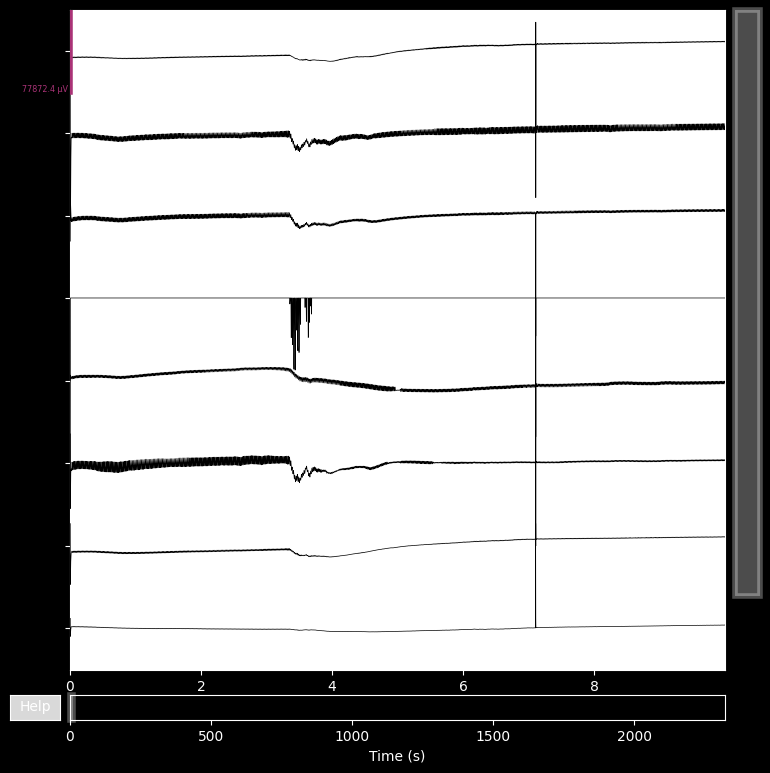

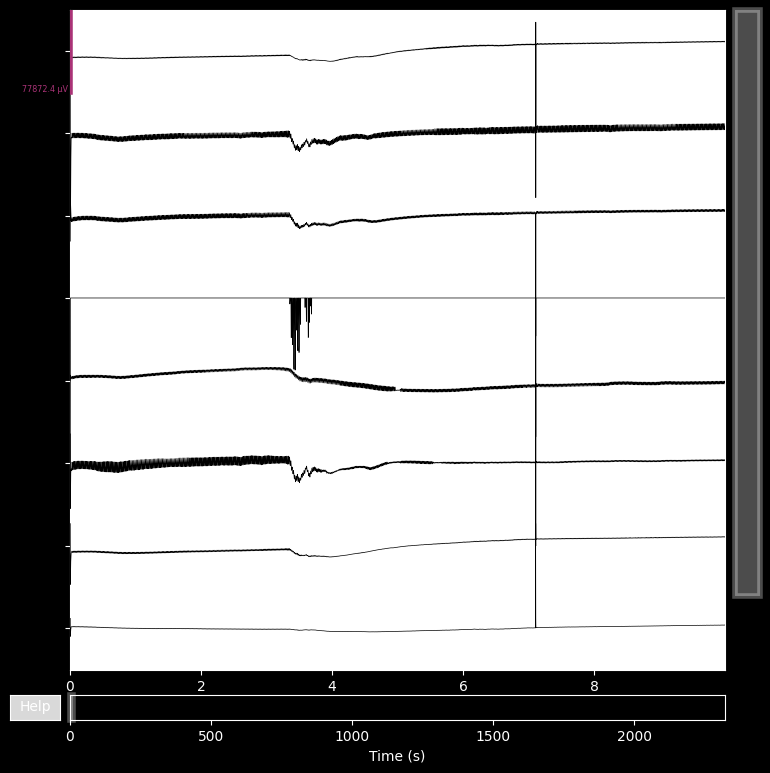

In [5]:
n_eeg = len(mne.pick_types(raw.info, eeg=True, exclude=[]))
n_show = min(16, max(n_eeg, 1))
raw.plot(n_channels=n_show, duration=10, scalings="auto", title="Raw (browse)")

## 2. 标准 10–20 蒙太奇（枕顶 8 导联）

与 `data_processing.ipynb` 中 `standard_1005` 不同，此处通道少，使用 **`standard_1020`** 即可覆盖 PO/Oz 等。

In [6]:
montage = mne.channels.make_standard_montage("standard_1020")
raw.set_montage(montage, match_case=False, on_missing="ignore")

<Raw | EEG_20260420_054313-raw.fif, 9 x 1160447 (2320.9 s), ~79.7 MiB, data loaded>

## 3. 功率谱密度（PSD）

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\.venv\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


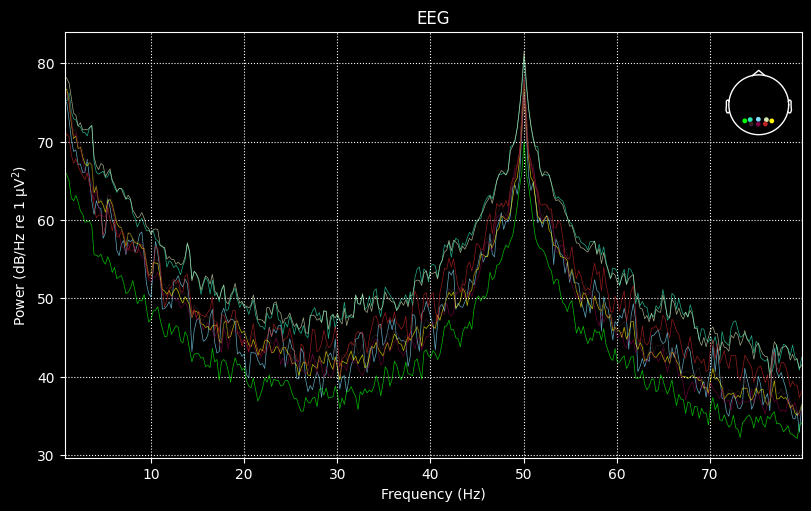

In [7]:
fig = raw.copy().pick(picks="eeg", exclude=[]).compute_psd(fmin=0.5, fmax=80).plot()
fig.set_size_inches(8, 5)
plt.show()

## 4. 陷波 + 带通（与参考笔记本流程一致）

工频 **50 Hz** 陷波；带通 **0.5–40 Hz**（可按需要改为 0.1–40 Hz）。仅对 **EEG** 通道滤波。

In [8]:
raw_filt = raw.copy()
raw_filt.notch_filter(50, picks="eeg", verbose=True)
raw_filt.filter(0.5, 40.0, picks="eeg", verbose=True)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 3301 samples (6.602 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband ed

<Raw | EEG_20260420_054313-raw.fif, 9 x 1160447 (2320.9 s), ~79.7 MiB, data loaded>

### 滤波前 / 后 PSD 对比（同参考笔记本的双图对比）

Effective window size : 4.096 (s)
Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).
Plotting power spectral density (dB=True).


C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\.venv\Lib\site-packages\mne\viz\evoked.py:238: UserWarning: Glyph 28388 (\N{CJK UNIFIED IDEOGRAPH-6EE4}) missing from font(s) DejaVu Sans.
  axis.get_figure().canvas.draw()
C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\.venv\Lib\site-packages\mne\viz\evoked.py:238: UserWarning: Glyph 27874 (\N{CJK UNIFIED IDEOGRAPH-6CE2}) missing from font(s) DejaVu Sans.
  axis.get_figure().canvas.draw()
C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\.venv\Lib\site-packages\mne\viz\evoked.py:238: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from font(s) DejaVu Sans.
  axis.get_figure().canvas.draw()
C:\Users\ROG\AppData\Local\Temp\ipykernel_24520\124417249.py:8: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\ROG\AppData\Local\Temp\ipykernel_24520\124417249.py:8: UserWarning: Glyph 28388 (\N{CJK UNIFIED IDEOGRAPH-6EE4}) missi

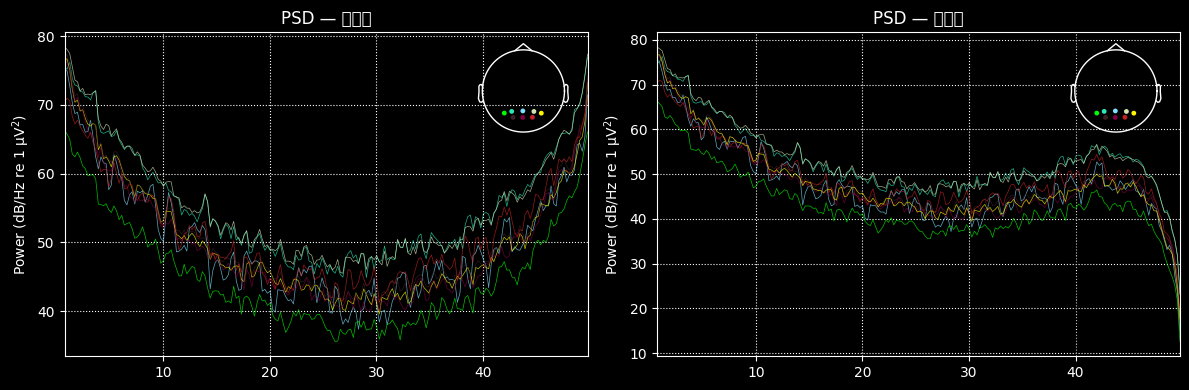

In [9]:
raw_psd = raw.copy().pick("eeg").compute_psd(fmin=0.5, fmax=50)
raw_filt_psd = raw_filt.copy().pick("eeg").compute_psd(fmin=0.5, fmax=50)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw_psd.plot(axes=axes[0], show=False)
axes[0].set_title("PSD — 滤波前")
raw_filt_psd.plot(axes=axes[1], show=False)
axes[1].set_title("PSD — 滤波后")
plt.tight_layout()
plt.show()

## 5. ICA（成分数 ≤ EEG 导联数）

八通道时 ICA 分量最多 8；若数据较短或噪声大，可适当减少 `n_components`。

In [10]:
n_comp = min(8, len(mne.pick_types(raw_filt.info, eeg=True)))
ica = mne.preprocessing.ICA(
    n_components=n_comp,
    random_state=97,
    max_iter="auto",
    method="fastica",
)
ica.fit(raw_filt, picks="eeg")

Fitting ICA to data using 8 channels (please be patient, this may take a while)
Selecting by number: 8 components
Fitting ICA took 7.9s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,42 iterations on raw data (1160447 samples)
ICA components,8
Available PCA components,8
Channel types,eeg
ICA components marked for exclusion,—


### 5.1 眼电 / 肌电 IC 自动剔除（可选）

- **ICA 拟合**：推荐在**滤波后的连续数据**上拟合（通常用**整段**），保证方差与统计稳定；若只在想象段拟合，数据可能过短或方差不足。
- **检测眼电/肌电**：可以只在**想象段**（TRIG 码 1/2）上算相关与肌电分数，更贴近任务期伪迹；**不是必须**，无 TRIG 时下面代码会退回全段。
- **无额叶 EOG**：枕区 8 导没有专用眼电时，`find_bads_eog` 必须指定**代理通道**（如 `Oz`），与真 EOG 相比**可靠性较低**，请用 `ica.plot_components` 等**人工复核**。
- **更强自动标注**：可额外安装 **`mne-icalabel`**（ICLabel）做多类成分分类（本单元未调用）。

In [ ]:
# 是否仅在「左/右想象」TRIG 段（码 1/2）上检测眼电/肌电相关 IC（无 TRIG 时自动退回全段）
USE_MI_ONLY_FOR_ICA_LABELS = False
# 无专用 EOG 通道时用作「伪眼电参考」的 EEG 通道名（枕顶区仅为近似）
EOG_PROXY_CH = "Oz"

def _raw_mi_segments_only(raw_inst, min_s=0.2):
    """若含 TRIG，则仅保留码为 1/2 的连续片段并拼接；否则返回原 raw。"""
    if "TRIG" not in raw_inst.ch_names:
        return raw_inst
    v = raw_inst.get_data(picks="TRIG")[0]
    codes = np.rint(v / TRIG_VOLT_SCALE).astype(np.int64)
    sfreq = float(raw_inst.info["sfreq"])
    min_len = int(min_s * sfreq)
    mi = np.isin(codes, [TRIG_MI_LEFT, TRIG_MI_RIGHT])
    raws = []
    i, n = 0, len(mi)
    while i < n:
        if not mi[i]:
            i += 1
            continue
        j = i
        while j < n and mi[j]:
            j += 1
        if j - i >= min_len:
            t0 = i / sfreq
            tmax = (j - 1) / sfreq
            raws.append(raw_inst.copy().crop(tmin=t0, tmax=tmax))
        i = j
    if not raws:
        print(f"未找到 ≥{min_s:.1f}s 的想象段，回退为全段用于检测")
        return raw_inst
    if len(raws) == 1:
        return raws[0]
    return mne.concatenate_raws(raws)

inst_detect = _raw_mi_segments_only(raw_filt) if USE_MI_ONLY_FOR_ICA_LABELS else raw_filt

eeg_picks = mne.pick_types(raw_filt.info, eeg=True)
if EOG_PROXY_CH not in raw_filt.ch_names:
    eog_ch = raw_filt.ch_names[eeg_picks[0]]
    print(f"注意: {EOG_PROXY_CH!r} 不在通道中，改用 {eog_ch!r} 作伪眼电参考")
else:
    eog_ch = EOG_PROXY_CH

eog_inds, _ = ica.find_bads_eog(inst_detect, ch_name=eog_ch)
mus_inds, _ = ica.find_bads_muscle(inst_detect, threshold=0.5)

ica.exclude = sorted(set(eog_inds) | set(mus_inds))
print("自动建议剔除 IC（眼电∪肌电，去重）:", ica.exclude)
print("  眼电相关子集:", eog_inds)
print("  肌电相关子集:", mus_inds)

In [11]:
ica.plot_components(inst=raw_filt, picks="eeg")

ValueError: picks as str can only be used when measurement info is available

Applying ICA to Raw instance
    Transforming to ICA space (8 components)
    Zeroing out 0 ICA components
    Projecting back using 8 PCA components
Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\.venv\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


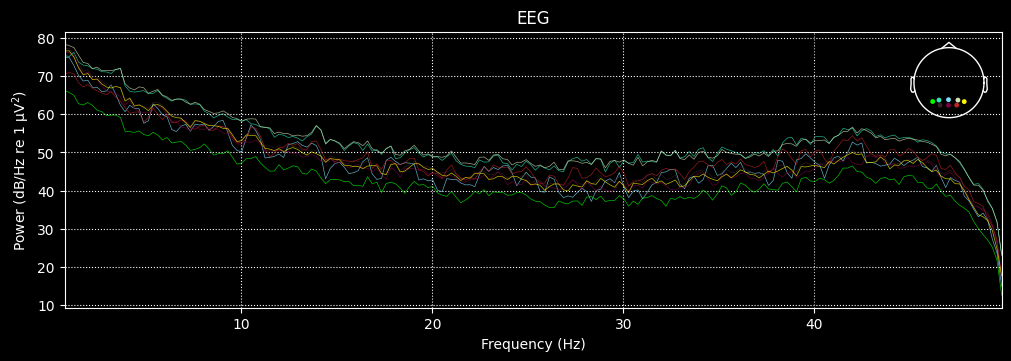

In [12]:
raw_ica = raw_filt.copy()
ica.apply(raw_ica)
raw_ica.compute_psd(fmin=0.5, fmax=50).plot()
plt.show()

## 6. TRIG 通道解析（与 `trigger_protocol.py` 一致）

FIF 中 TRIG 存盘：`value_V = code * TRIG_VOLT_SCALE`，解码：`code = rint(V / TRIG_VOLT_SCALE)`。

| 码 | 含义 |
|---|---|
| 0 | OFF |
| 1 | MI 左 |
| 2 | MI 右 |
| 10 | 休息 |
| 11 | 准备 |

下面用 MNE 读 `TRIG` 连续量并解码；**Epoch** 默认在 **左/右想象码出现沿**（1 或 2）建事件。纯 **EDF** 且无 `TRIG` 名通道时跳过。

In [13]:
def decode_trig_volts(volts_1d):
    """与 trigger_protocol 文档一致：整数码 = rint(伏特 / TRIG_VOLT_SCALE)。"""
    return np.rint(np.asarray(volts_1d, dtype=np.float64) / TRIG_VOLT_SCALE).astype(np.int64)


def trig_codes_from_raw(raw_inst):
    """读取名为 TRIG 的通道，返回每个采样点的码序列（与 FIFO_plot 写入一致）。"""
    names = raw_inst.ch_names
    if "TRIG" not in names:
        return None, None
    idx = names.index("TRIG")
    volts = raw_inst.get_data(picks=[idx])[0]
    codes = decode_trig_volts(volts)
    return codes, idx


def summarize_trig_codes(codes):
    """按 trigger_protocol 标注各码含义并统计采样点数。"""
    labels = {
        TRIG_OFF: "OFF",
        TRIG_MI_LEFT: "MI_LEFT",
        TRIG_MI_RIGHT: "MI_RIGHT",
        TRIG_REST: "REST",
        TRIG_PREP: "PREP",
    }
    uniq, counts = np.unique(codes, return_counts=True)
    print("TRIG 解码统计（trigger_protocol 码表）:")
    for u, n in zip(uniq, counts):
        u = int(u)
        name = labels.get(u, f"other({u})")
        print(f"  code={u:3d}  {name:12s}  n_samples={int(n)}")


def build_events_from_trig(codes, codes_interest=(TRIG_MI_LEFT, TRIG_MI_RIGHT)):
    """在码从「非兴趣」变为「左/右想象」的采样点生成 MNE events（event_id 用码值）。"""
    interest = set(codes_interest)
    events = []
    prev = -99999
    for i, c in enumerate(codes):
        c = int(c)
        if c in interest and int(prev) not in interest:
            events.append([i, 0, c])
        prev = c
    if not events:
        return np.empty((0, 3), dtype=int)
    return np.array(events, dtype=int)


# TRIG 与滤波后数据一致；用 raw_filt 解码，避免未先运行 ICA apply 时 raw_ica 未定义
codes, _ = trig_codes_from_raw(raw_filt)
sfreq = raw_filt.info["sfreq"]

if codes is None:
    print("未找到 TRIG 通道：跳过。可检查通道名或改用 annotations。")
    events = None
    event_id = None
else:
    summarize_trig_codes(codes)
    events = build_events_from_trig(
        codes, codes_interest=(TRIG_MI_LEFT, TRIG_MI_RIGHT)
    )
    event_id = {"left": TRIG_MI_LEFT, "right": TRIG_MI_RIGHT}
    print("\n左/右想象 onset events 形状:", events.shape, "sfreq=", sfreq)
    if len(events):
        print("前 10 行 [sample, prev_id, event_id]:")
        print(events[:10])

TRIG 解码统计（trigger_protocol 码表）:
  code=  0  OFF           n_samples=408409
  code=  1  MI_LEFT       n_samples=157198
  code=  2  MI_RIGHT      n_samples=189379
  code= 10  REST          n_samples=278175
  code= 11  PREP          n_samples=127286

左/右想象 onset events 形状: (170, 3) sfreq= 500.0
前 10 行 [sample, prev_id, event_id]:
[[29105     0     2]
 [33354     0     2]
 [37572     0     1]
 [41822     0     2]
 [46071     0     1]
 [50321     0     1]
 [54571     0     1]
 [58821     0     1]
 [63070     0     1]
 [67319     0     1]]


Not setting metadata
170 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 170 events and 601 original time points ...
0 bad epochs dropped
<Epochs | 170 events (all good), -0.2 – 1 s (baseline -0.2 – 0 s), ~6.3 MiB, data loaded,
 'left': 79
 'right': 91>


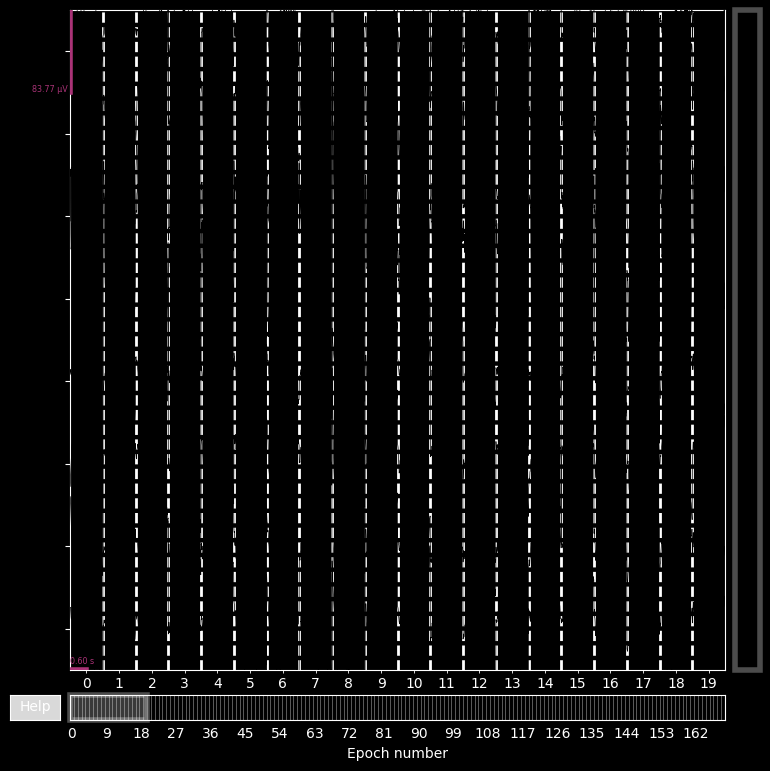

In [14]:
if events is not None and len(events) > 0:
    # 若已运行 ICA apply 则有 raw_ica；否则用 raw_filt（未去 ICA 伪迹）
    _epochs_src = globals().get("raw_ica", raw_filt)
    epochs = mne.Epochs(
        _epochs_src,
        events,
        event_id=event_id,
        tmin=-0.2,
        tmax=1.0,
        baseline=(-0.2, 0),
        picks="eeg",
        preload=True,
        verbose=True,
    )
    print(epochs)
    epochs.plot(n_channels=len(epochs.ch_names), scalings="auto")
else:
    epochs = None
    print("无 events，未创建 Epochs。")

## 7. 按条件平均 ERP / 诱发电位（与参考笔记本 `evokeds` 类似）

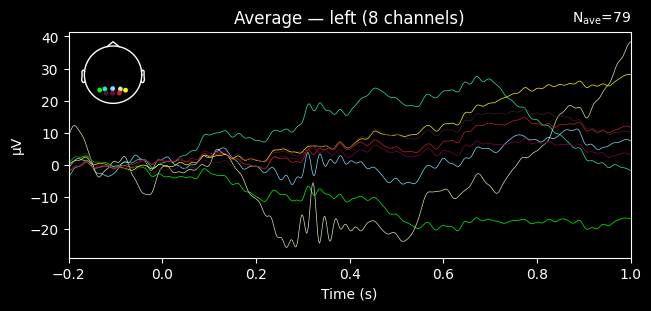

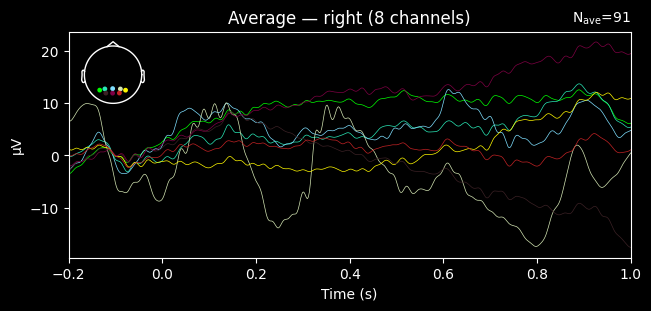

combining channels using GFP (eeg channels)
combining channels using GFP (eeg channels)


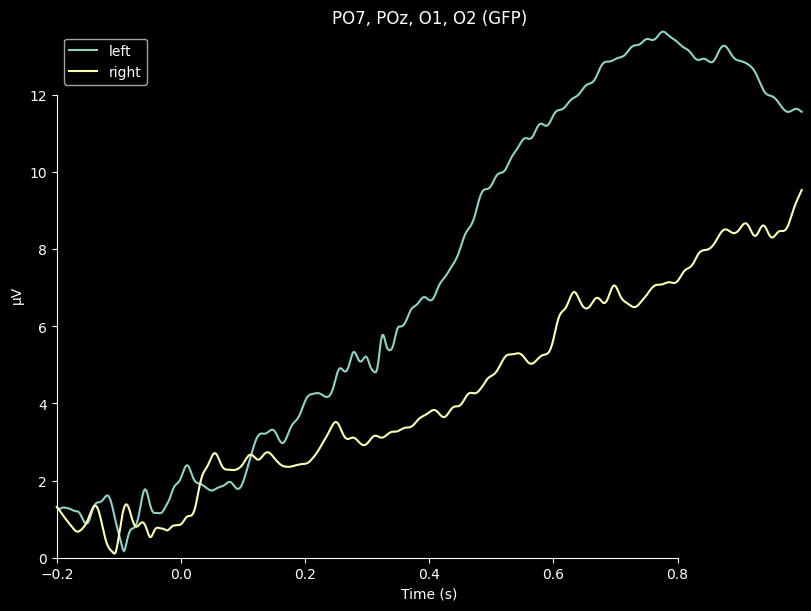

In [15]:
if epochs is not None and len(epochs) > 0:
    evokeds = {}
    for cond, eid in event_id.items():
        if eid in epochs.event_id.values():
            evokeds[cond] = epochs[cond].average()
    for cond, evo in evokeds.items():
        evo.plot(spatial_colors=True, titles=dict(eeg=f"Average — {cond}"))
    if len(evokeds) >= 2:
        mne.viz.plot_compare_evokeds(evokeds, picks=["PO7", "POz", "O1", "O2"], legend="upper left")
else:
    print("无 epochs，跳过 evoked 对比。")

## 8. 导出 NPZ（与 `data_processing.ipynb` 中 trial 级保存一致）

- **`X`**：形状 `(N, C, T)`，与参考笔记本中 **`Xz` 相同**——对每个 trial、每个通道在时间维上做 z-score（`eps=1e-8`）；单位为无量纲。
- **`y`**：`0` = 左（TRIG 1）、`1` = 右（TRIG 2）；**`trig_codes`** 保存原始事件码 1/2。
- **`event_id_json`**：`event_id` 的 JSON 字符串，便于 `json.loads` 还原。
- 默认保存路径：**`data_process/out/<录制 stem>_mi.npz`**（自动建目录）。

In [16]:
# 与 data_processing.ipynb：X = get_data → 按 trial×通道 对时间维 z-score → savez_compressed
import json

if epochs is not None and len(epochs) > 0 and event_id is not None:
    X = epochs.get_data()  # (n_epochs, n_channels, n_times)，伏特
    trig_codes = epochs.events[:, 2].astype(np.int64)
    y = trig_codes - 1  # 0=左, 1=右（对应 TRIG 1/2）

    eps = 1e-8
    mean = X.mean(axis=2, keepdims=True)
    std = X.std(axis=2, keepdims=True)
    Xz = (X - mean) / (std + eps)

    _export_dir = PROJECT_ROOT / "data_process" / "out"
    _export_dir.mkdir(parents=True, exist_ok=True)
    _stem = Path(DATA_PATH).stem.replace("-raw", "")
    out_path = _export_dir / f"{_stem}_mi.npz"

    np.savez_compressed(
        out_path,
        X=Xz.astype(np.float32),
        y=y.astype(np.int64),
        trig_codes=trig_codes,
        sfreq=np.float32(epochs.info["sfreq"]),
        ch_names=np.array(epochs.ch_names, dtype=object),
        times=epochs.times.astype(np.float32),
        event_id_json=np.array(json.dumps(event_id, ensure_ascii=False)),
        tmin=np.float32(epochs.tmin),
        tmax=np.float32(epochs.tmax),
    )
    print("saved:", out_path.resolve())
    print("  X shape:", Xz.shape, "y:", y.shape, np.unique(y, return_counts=True))
    _d = np.load(out_path, allow_pickle=True)
    print("load check:", _d["X"].shape, _d["y"].shape, "sfreq:", float(_d["sfreq"]))
else:
    print("无 epochs 或 event_id，跳过 NPZ 导出。")

saved: C:\Users\ROG\Documents\PlatformIO\Projects\EEG_Test\data_process\out\EEG_20260420_054313_mi.npz
  X shape: (170, 8, 601) y: (170,) (array([0, 1]), array([79, 91]))
load check: (170, 8, 601) (170,) sfreq: 500.0


---
### 说明

- **EDF**：若由外部软件导出，通道名可能与 `EEG_CH_NAMES` 不一致，可在加载后使用 `raw.rename_channels(dict)` 对齐。  
- **FIF（本仓库采集）**：通常为 9 通道（8 EEG + TRIG）；TRIG 按 `trigger_protocol.TRIG_VOLT_SCALE` 解码，码表见第 6 节。  
- **NPZ**：第 8 节将分段数据导出至 `data_process/out/*_mi.npz`（与 `data_processing.ipynb` 中 trial 级 `Xz`/`y` 约定一致）。  
- 若你希望 **统一只分析 EDF**，请先将 FIF 转为 EDF，例如：  
  `raw.export("out.edf", fmt="edf")`（需 MNE 支持导出，且通道类型兼容）。